# Data loading and Cleaning

In [67]:
import numpy as np
import pandas as pd
import seaborn as sns
import glob
import os
import joblib
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    auc,
    roc_curve,
    confusion_matrix,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.preprocessing import QuantileTransformer, RobustScaler
from sklearn.model_selection import ParameterGrid

In [2]:
# loading
assets = joblib.load("nids_iso_forest_pipeline.pkl")
iso_model = assets["iso_model"]
selected_thresh = assets["selected_thresh"]
selected_cols = assets["selected_cols"]
scaler = assets["scaler"]

data = np.load("scaled_datasets.npz")
X_train_scaled = data["X_train"]
X_val_scaled = data["X_val"]
X_test_scaled = data["X_test"]
y_train, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]

print("laoding done")

laoding done


In [2]:
fast_raw_file = "../data/raw/merged_raw.parquet"

if os.path.exists(fast_raw_file):
    print("Loading fast merged raw data...")
    df = pd.read_parquet(fast_raw_file)

else:
    print("Loading CSV files for the first time...")
    path = "../data/raw/*.csv"
    all_files = glob.glob(path)

    df = pd.concat((pd.read_csv(f) for f in all_files), ignore_index=True)

    print("Saving merged data to Parquet in raw folder...")
    df.to_parquet(fast_raw_file, index=False)

print(f"Data successfully loaded! Shape: {df.shape}")

Loading fast merged raw data...
Data successfully loaded! Shape: (2830743, 79)


In [3]:
df.shape

(2830743, 79)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   Flow IAT Max                 int

In [5]:
df.describe()

c:\Users\user\anaconda3\envs\ai_net_env\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\user\anaconda3\envs\ai_net_env\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,...,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06
mean,8.071483e+03,1.478566e+07,9.361160e+00,1.039377e+01,5.493024e+02,1.616264e+04,2.075999e+02,1.871366e+01,5.820194e+01,6.891013e+01,...,5.418218e+00,-2.741688e+03,8.155132e+04,4.113412e+04,1.531825e+05,5.829582e+04,8.316037e+06,5.038439e+05,8.695752e+06,7.920031e+06
std,1.828363e+04,3.365374e+07,7.496728e+02,9.973883e+02,9.993589e+03,2.263088e+06,7.171848e+02,6.033935e+01,1.860912e+02,2.811871e+02,...,6.364257e+02,1.084989e+06,6.485999e+05,3.933815e+05,1.025825e+06,5.770923e+05,2.363008e+07,4.602984e+06,2.436689e+07,2.336342e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,1.550000e+02,2.000000e+00,1.000000e+00,1.200000e+01,0.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,3.131600e+04,2.000000e+00,2.000000e+00,6.200000e+01,1.230000e+02,3.700000e+01,2.000000e+00,3.400000e+01,0.000000e+00,...,1.000000e+00,2.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,3.204828e+06,5.000000e+00,4.000000e+00,1.870000e+02,4.820000e+02,8.100000e+01,3.600000e+01,5.000000e+01,2.616295e+01,...,2.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


In [7]:
df.columns.tolist()

[' Destination Port',
 ' Flow Duration',
 ' Total Fwd Packets',
 ' Total Backward Packets',
 'Total Length of Fwd Packets',
 ' Total Length of Bwd Packets',
 ' Fwd Packet Length Max',
 ' Fwd Packet Length Min',
 ' Fwd Packet Length Mean',
 ' Fwd Packet Length Std',
 'Bwd Packet Length Max',
 ' Bwd Packet Length Min',
 ' Bwd Packet Length Mean',
 ' Bwd Packet Length Std',
 'Flow Bytes/s',
 ' Flow Packets/s',
 ' Flow IAT Mean',
 ' Flow IAT Std',
 ' Flow IAT Max',
 ' Flow IAT Min',
 'Fwd IAT Total',
 ' Fwd IAT Mean',
 ' Fwd IAT Std',
 ' Fwd IAT Max',
 ' Fwd IAT Min',
 'Bwd IAT Total',
 ' Bwd IAT Mean',
 ' Bwd IAT Std',
 ' Bwd IAT Max',
 ' Bwd IAT Min',
 'Fwd PSH Flags',
 ' Bwd PSH Flags',
 ' Fwd URG Flags',
 ' Bwd URG Flags',
 ' Fwd Header Length',
 ' Bwd Header Length',
 'Fwd Packets/s',
 ' Bwd Packets/s',
 ' Min Packet Length',
 ' Max Packet Length',
 ' Packet Length Mean',
 ' Packet Length Std',
 ' Packet Length Variance',
 'FIN Flag Count',
 ' SYN Flag Count',
 ' RST Flag Count',
 ' P

In [6]:
# delete any space and turn features to lowercase
df.columns = df.columns.str.strip().str.lower()

In [9]:
df.columns.tolist()

['destination port',
 'flow duration',
 'total fwd packets',
 'total backward packets',
 'total length of fwd packets',
 'total length of bwd packets',
 'fwd packet length max',
 'fwd packet length min',
 'fwd packet length mean',
 'fwd packet length std',
 'bwd packet length max',
 'bwd packet length min',
 'bwd packet length mean',
 'bwd packet length std',
 'flow bytes/s',
 'flow packets/s',
 'flow iat mean',
 'flow iat std',
 'flow iat max',
 'flow iat min',
 'fwd iat total',
 'fwd iat mean',
 'fwd iat std',
 'fwd iat max',
 'fwd iat min',
 'bwd iat total',
 'bwd iat mean',
 'bwd iat std',
 'bwd iat max',
 'bwd iat min',
 'fwd psh flags',
 'bwd psh flags',
 'fwd urg flags',
 'bwd urg flags',
 'fwd header length',
 'bwd header length',
 'fwd packets/s',
 'bwd packets/s',
 'min packet length',
 'max packet length',
 'packet length mean',
 'packet length std',
 'packet length variance',
 'fin flag count',
 'syn flag count',
 'rst flag count',
 'psh flag count',
 'ack flag count',
 'ur

In [10]:
df["label"].value_counts()

label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [11]:
class_percentage = df["label"].value_counts(normalize = True)* 100
print(class_percentage)

label
BENIGN                        80.300366
DoS Hulk                       8.162981
PortScan                       5.614427
DDoS                           4.522735
DoS GoldenEye                  0.363615
FTP-Patator                    0.280421
SSH-Patator                    0.208320
DoS slowloris                  0.204752
DoS Slowhttptest               0.194260
Bot                            0.069452
Web Attack � Brute Force       0.053237
Web Attack � XSS               0.023033
Infiltration                   0.001272
Web Attack � Sql Injection     0.000742
Heartbleed                     0.000389
Name: proportion, dtype: float64


In [12]:
df.duplicated().sum()

np.int64(308381)

In [13]:
duplicate_rows = df[df.duplicated()]

In [14]:
duplicate_rows

,destination port,flow duration,total fwd packets,total backward packets,total length of fwd packets,total length of bwd packets,fwd packet length max,fwd packet length min,fwd packet length mean,fwd packet length std,...,min_seg_size_forward,active mean,active std,active max,active min,idle mean,idle std,idle max,idle min,label
2109,80,77,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2257,443,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2749,443,49,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2862,443,4,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2877,443,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2830701,53,179,2,2,46,46,23,23,23.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830725,53,161,2,2,82,114,41,41,41.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830726,53,212,2,2,84,162,42,42,42.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830731,443,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [15]:
for label_name in df["label"].unique():
    class_subset = df[df["label"] == label_name]

    dups_count = class_subset.duplicated().sum()
    total_count = len(class_subset)

    print(
        f"Class: [{label_name}] --> Total: {total_count} rows | Duplicates: {dups_count} rows"
    )

Class: [BENIGN] --> Total: 2273097 rows | Duplicates: 176613 rows
Class: [DDoS] --> Total: 128027 rows | Duplicates: 11 rows
Class: [PortScan] --> Total: 158930 rows | Duplicates: 68111 rows
Class: [Bot] --> Total: 1966 rows | Duplicates: 13 rows
Class: [Infiltration] --> Total: 36 rows | Duplicates: 0 rows
Class: [Web Attack � Brute Force] --> Total: 1507 rows | Duplicates: 37 rows
Class: [Web Attack � XSS] --> Total: 652 rows | Duplicates: 0 rows
Class: [Web Attack � Sql Injection] --> Total: 21 rows | Duplicates: 0 rows
Class: [FTP-Patator] --> Total: 7938 rows | Duplicates: 2005 rows
Class: [SSH-Patator] --> Total: 5897 rows | Duplicates: 2678 rows
Class: [DoS slowloris] --> Total: 5796 rows | Duplicates: 411 rows
Class: [DoS Slowhttptest] --> Total: 5499 rows | Duplicates: 271 rows
Class: [DoS Hulk] --> Total: 231073 rows | Duplicates: 58224 rows
Class: [DoS GoldenEye] --> Total: 10293 rows | Duplicates: 7 rows
Class: [Heartbleed] --> Total: 11 rows | Duplicates: 0 rows


In [7]:
df_clean = df.copy()

In [17]:
benign_class_name = "BENIGN"  

df_benign = df_clean[df_clean["label"] == benign_class_name]
df_attacks = df_clean[df_clean["label"] != benign_class_name]

print(f"Benign: {len(df_benign)}")
print(f"Attack: {len(df_attacks)}")

Benign: 2273097
Attack: 557646


In [8]:
df_clean.duplicated().sum()

np.int64(308381)

In [9]:
df_clean = df_clean.drop_duplicates()

In [10]:
df_clean.duplicated().sum()

np.int64(0)

In [21]:
# Function to Inspect Nulls and Inf Values
def inspect_inf_and_nan(df, label_col="label"):
    """Fast vectorized inspection for Inf and NaN values in dataframe features."""
    df_temp = df.copy()
    report = []
    total_rows = len(df_temp)

    # Select feature columns (exclude label column)
    feature_cols = [col for col in df_temp.columns if col != label_col]

    for col in feature_cols:
        # Fast vectorized numeric conversion
        num_series = pd.to_numeric(df_temp[col], errors="coerce")
        n_inf = np.isinf(num_series).sum()
        n_nan = num_series.isna().sum()

        if n_inf > 0 or n_nan > 0:
            report.append(
                {
                    "column": col,
                    "inf_count": n_inf,
                    "inf_%": round((n_inf / total_rows) * 100, 4),
                    "nan_count": n_nan,
                    "nan_%": round((n_nan / total_rows) * 100, 4),
                    "total_corrupted": n_inf + n_nan,
                }
            )

    report_df = pd.DataFrame(report)
    print("=" * 65)
    print("Report For Nulls And Infinity Values")
    print("=" * 65)

    if not report_df.empty:
        report_df = report_df.sort_values(by="total_corrupted", ascending=False)
        print(report_df.to_string(index=False))
    else:
        print("There are no NaN or Inf values found.")

    return report_df

In [22]:
report_df = inspect_inf_and_nan(df_clean, label_col="label")

Report For Nulls And Infinity Values
        column  inf_count  inf_%  nan_count  nan_%  total_corrupted
  flow bytes/s       1211  0.048        353  0.014             1564
flow packets/s       1564  0.062          0  0.000             1564


In [11]:
# ب. معالجة وتوحيد تحويل الأعمدة العدديدية وتحديد الـ Infs كـ NaNs شمولية
numeric_cols = [col for col in df_clean.columns if col != "label"]
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# ج. تحديد قناع شامل لكل الصفوف التالفة (NaN أو Inf) عبر جميع الميزات
corrupted_mask = df_clean[numeric_cols].isna().any(axis=1) | np.isinf(
    df_clean[numeric_cols]
).any(axis=1)

In [12]:
# numbers of Nulls in each class in columne = label
print(df_clean[corrupted_mask]["label"].value_counts())

label
BENIGN         1427
PortScan        125
Bot               5
DoS Hulk          3
DDoS              2
FTP-Patator       2
Name: count, dtype: int64


In [25]:
df_clean['label'].value_counts()

label
BENIGN                        2096484
DoS Hulk                       172849
DDoS                           128016
PortScan                        90819
DoS GoldenEye                   10286
FTP-Patator                      5933
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1953
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [26]:
print("Percentage Loss Per Class Before Dropping:")

total_per_class = df_clean["label"].value_counts()
corrupted_per_class = df_clean[corrupted_mask]["label"].value_counts()
percentage_loss = (corrupted_per_class / total_per_class) * 100
print(percentage_loss.dropna().round(4).astype(str) + " %")

Percentage Loss Per Class Before Dropping:
label
BENIGN         0.0681 %
Bot             0.256 %
DDoS           0.0016 %
DoS Hulk       0.0017 %
FTP-Patator    0.0337 %
PortScan       0.1376 %
Name: count, dtype: str


In [27]:
# Now we can remove nulls and we are reassured
# need to handle those tow columnes in Online Preprocessing Pipeline

In [13]:
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)
print(f"number of raws before drop: {len(df_clean):,}")

df_clean.dropna(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print(f"Number of rows after dropping nulls/infs: {len(df_clean):,}")

number of raws before drop: 2,522,362
Number of rows after dropping nulls/infs: 2,520,798


In [14]:
print(f"number of NaNs is {2522362 - 2520798}")

number of NaNs is 1564


# splitting

In [15]:
from sklearn.model_selection import train_test_split
y = df_clean['label'].apply(lambda x: 0 if str(x).strip().upper() == 'BENIGN' else 1)

In [16]:
if df_clean["fwd header length"].equals(df_clean["fwd header length.1"]): 
    print("YES") 
else: 
    print("NO")

YES


In [17]:
cols_to_drop = ['label', 'destination port', 'fwd header length.1']
X = df_clean.drop(columns=[col for col in cols_to_drop if col in df_clean.columns])

In [18]:
# (Stratified Train/Val/Test Split) 
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

In [19]:
# Train (70%) and Validation (15%)
# 15/85 = .17647
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.17647, random_state=42, stratify=y_train_val
)

In [47]:
print(f" {X_train.shape}")
print(f" {X_val.shape}")
print(f" {X_test.shape}")

 (1764559, 76)
 (378119, 76)
 (378120, 76)


In [21]:
X_train_prep = X_train.copy()
X_val_prep = X_val.copy()
X_test_prep = X_test.copy()

# Feature Selection

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from boruta import BorutaPy

# Pearson
def remove_pearson_redundant_features(X_data, threshold):
    corr_matrix = X_data.corr(method="pearson").abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = [
        column for column in upper_tri.columns if any(upper_tri[column] > threshold)
    ]
    df_reduced = X_data.drop(columns=to_drop)

    print(
        f"Pearson Filter: Removed {len(to_drop)} redundant features. Remaining: {df_reduced.shape[1]}"
    )
    return df_reduced, to_drop

# Mi + Brouta
def run_mi_boruta_feature_selection(
    X, y, mode="strict", mi_threshold=0.05, sample_size=150000, max_iter=50
):
    """
    mode: 'strict' (perc=100, alpha=0.01) 
          'relaxed' (perc=80, alpha=0.1) 
    """
    if len(X) > sample_size:
        print(f"\nSubsampling {sample_size:,} records for fast {mode} evaluation...")
        X_sample, _, y_sample, _ = train_test_split(
            X, y, train_size=sample_size, stratify = y, random_state=42
        )
    else:
        X_sample, y_sample = X, y

    # MI Pre-filtering
    print(f"Calculating Mutual Information")
    mi_scores = mutual_info_classif(
        X_sample, y_sample, discrete_features="auto", random_state=42
    )
    mi_series = pd.Series(mi_scores, index=X_sample.columns).sort_values(
        ascending=False
    )

    current_mi_thresh = mi_threshold if mode == "strict" else (mi_threshold * 0.5)

    mi_passed_cols = mi_series[mi_series > current_mi_thresh].index.tolist()
    print(
        f"Features passing MI pre-filter ({current_mi_thresh}): {len(mi_passed_cols)}"
    )

    X_mi_subset = X_sample[mi_passed_cols].copy()

    boruta_perc = 100 if mode == "strict" else 80
    boruta_alpha = 0.01 if mode == "strict" else 0.1

    print(
        f"Running {mode.upper()} Boruta (perc={boruta_perc}, alpha={boruta_alpha})..."
    )
    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42,
    )

    boruta_selector = BorutaPy(
        estimator=rf,
        n_estimators="auto",
        alpha=boruta_alpha,
        perc=boruta_perc,
        max_iter=max_iter,
        random_state=42,
        verbose=0,  # خليتها 0 عشان الزحمة، 
    )

    boruta_selector.fit(X_mi_subset.values, y_sample.values)

    # اختيار الميزات
    confirmed_mask = boruta_selector.support_
    selected_cols = np.array(mi_passed_cols)[confirmed_mask].tolist()

    if mode == "relaxed":
        tentative_mask = boruta_selector.support_weak_
        tentative_cols = np.array(mi_passed_cols)[tentative_mask].tolist()
        selected_cols = list(set(selected_cols + tentative_cols))
        print(f"Included Tentative features for relaxed mode.")

    print(
        f" {mode.upper()} MI-Boruta Selection Complete! Selected {len(selected_cols)} features."
    )
    return selected_cols

In [34]:
X_train_pearson, dropped_pearson = remove_pearson_redundant_features(
    X_train_prep, threshold=0.9
)

print("\nExtracting STRICT Features")
strict_features = run_mi_boruta_feature_selection(
    X_train_pearson, y_train, mode="strict", mi_threshold=0.1
)

print("\nExtracting RELAXED Features")
relaxed_features = run_mi_boruta_feature_selection(
    X_train_pearson, y_train, mode="relaxed", mi_threshold=0.08
)

feature_sets = {"strict": strict_features, "relaxed": relaxed_features}
joblib.dump(feature_sets, "mi_boruta_feature_sets.joblib")
print("\nSaved both feature sets to 'mi_boruta_feature_sets.joblib'")

Pearson Filter: Removed 30 redundant features. Remaining: 46

Extracting STRICT Features

Subsampling 150,000 records for fast strict evaluation...
Calculating Mutual Information
Features passing MI pre-filter (0.1): 21
Running STRICT Boruta (perc=100, alpha=0.01)...
 STRICT MI-Boruta Selection Complete! Selected 21 features.

Extracting RELAXED Features

Subsampling 150,000 records for fast relaxed evaluation...
Calculating Mutual Information
Features passing MI pre-filter (0.04): 27
Running RELAXED Boruta (perc=80, alpha=0.1)...
Included Tentative features for relaxed mode.
 RELAXED MI-Boruta Selection Complete! Selected 27 features.

Saved both feature sets to 'mi_boruta_feature_sets.joblib'


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_correlation_heatmap(df, features, title):
    plt.figure(figsize=(14, 10))
    subset_df = df[features]
    corr_matrix = subset_df.corr()

    sns.heatmap(
        corr_matrix,
        annot=False,  
        cmap="coolwarm", 
        vmin=-1,
        vmax=1,
        center=0,  
        linewidths=0.5,  
        linecolor="white",
    )

    plt.title(title, fontsize=16, pad=20)
    plt.xticks(rotation=90)  
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

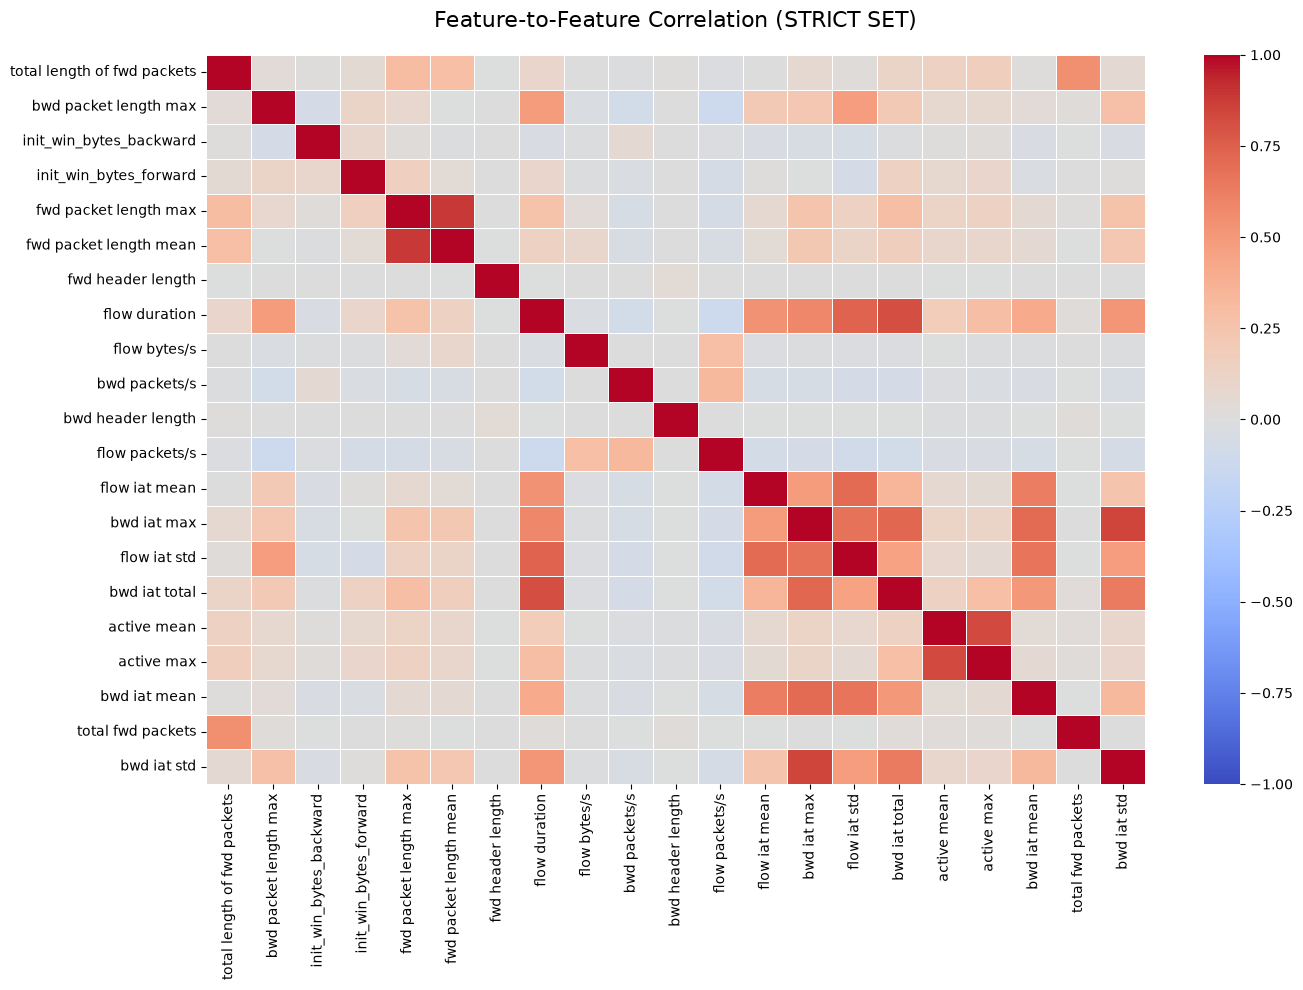

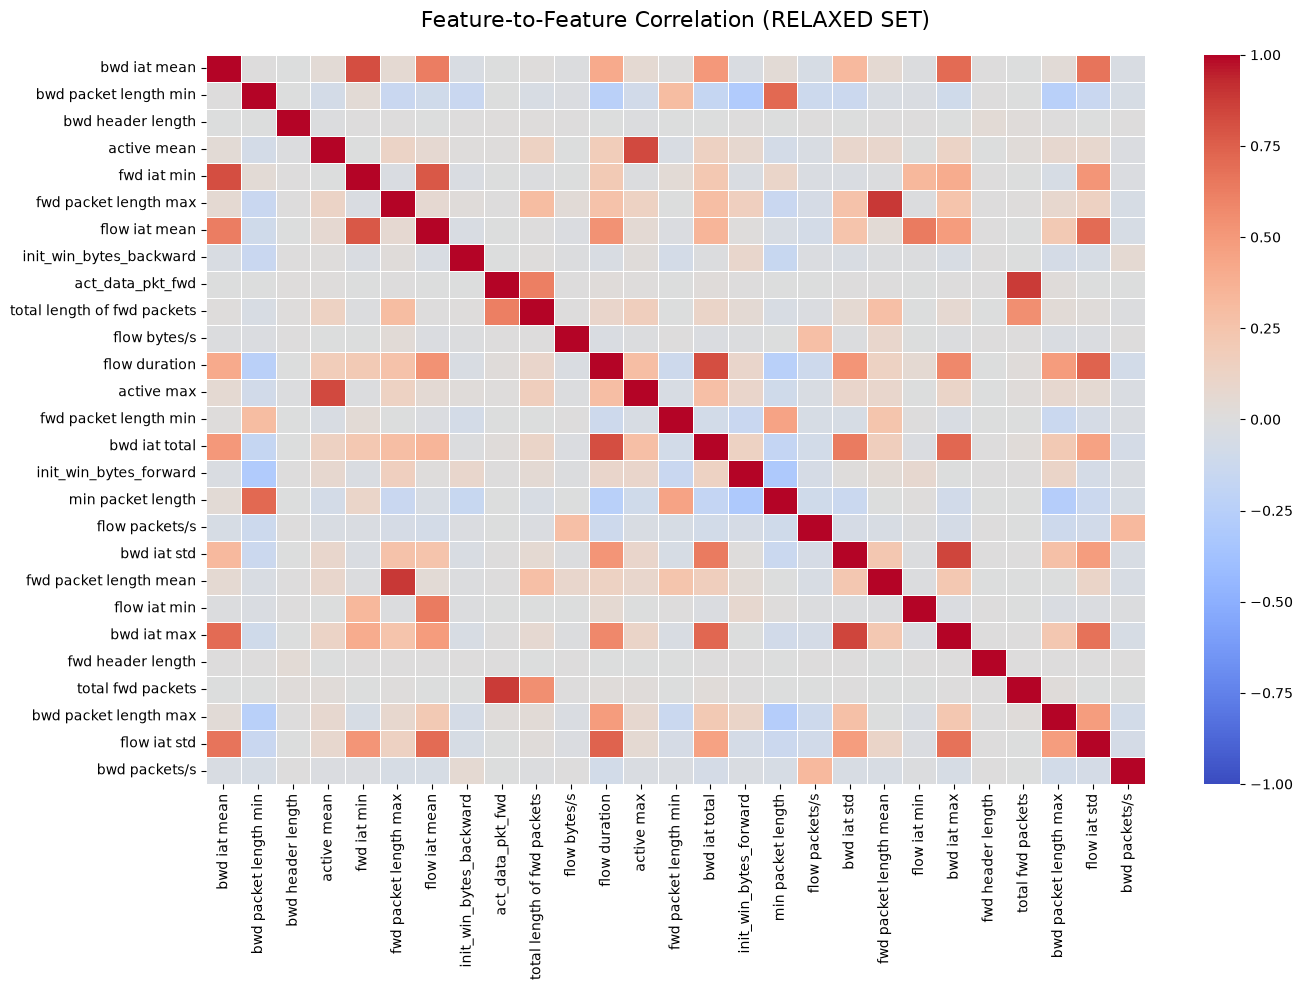

In [36]:
plot_correlation_heatmap(
    df=X_train_pearson,
    features=strict_features,
    title="Feature-to-Feature Correlation (STRICT SET)",
)

plot_correlation_heatmap(
    df=X_train_pearson,
    features=relaxed_features,
    title="Feature-to-Feature Correlation (RELAXED SET)",
)

# scaling

In [ ]:
train_medians = X_train_prep[strict_features].median()

X_tr_strict = X_train_prep[strict_features].copy().fillna(train_medians)
X_va_strict = X_val_prep[strict_features].copy().fillna(train_medians)
X_te_strict = X_test_prep[strict_features].copy().fillna(train_medians)

X_tr_relaxed = X_train_prep[relaxed_features].copy().fillna(train_medians)
X_va_relaxed = X_val_prep[relaxed_features].copy().fillna(train_medians)
X_te_relaxed = X_test_prep[relaxed_features].copy().fillna(train_medians)

# (Log Only)
def apply_log_transform(x_tr, x_va, x_te):
    x_tr_log = x_tr.copy()
    x_va_log = x_va.copy()
    x_te_log = x_te.copy()

    skewness_scores = x_tr_log.skew().abs()
    high_skew_cols = skewness_scores[skewness_scores > 2].index.tolist()

    forced_keywords = [
        "bytes",
        "packets",
        "duration",
        "iat",
        "length",
        "size",
        "active",
        "idle",
    ]
    forced_log_cols = [
        col
        for col in x_tr_log.columns
        if any(k in col.lower() for k in forced_keywords)
    ]

    final_log_cols = list(set(high_skew_cols + forced_log_cols))

    print(
        f"Applying Log Transformation to {len(final_log_cols)} skewed/network"
        " features..."
    )

    for col in final_log_cols:
        x_tr_log[col] = np.log1p(x_tr_log[col].clip(lower=0))
        x_va_log[col] = np.log1p(x_va_log[col].clip(lower=0))
        x_te_log[col] = np.log1p(x_te_log[col].clip(lower=0))

    return x_tr_log, x_va_log, x_te_log

# Log Transform
X_tr_strict_log, X_va_strict_log, X_te_strict_log = apply_log_transform(
    X_tr_strict, X_va_strict, X_te_strict
)
X_tr_relaxed_log, X_va_relaxed_log, X_te_relaxed_log = apply_log_transform(
    X_tr_relaxed, X_va_relaxed, X_te_relaxed
)

Applying Log Transformation to 21 skewed/network features...
Applying Log Transformation to 27 skewed/network features...
Applying RobustScaler on Log-transformed features...
All preprocessing variables (Raw, Log Only, Log + RobustScaler) are ready for GridSearch!


In [62]:
all_skewness = X_tr_strict.skew().abs()
high_skew_cols = all_skewness[all_skewness > 2].index.tolist()
escaped_cols = all_skewness[all_skewness <= 2].index.tolist()

print(f" (Skew > 2): {len(high_skew_cols)}")
print(f" (Skew <= 2): {len(escaped_cols)}\n")
print("(Escaped Columns):")

report_data = []
for col in escaped_cols:
    max_val = X_tr_strict[col].max()
    min_val = X_tr_strict[col].min()
    skew_val = all_skewness[col]

    report_data.append(
        {
            "Column Name": col,
            "Skewness": round(skew_val, 4),
            "Max Value": max_val,
            "Min Value": min_val,
        }
    )

escaped_df = pd.DataFrame(report_data).sort_values(by="Max Value", ascending=False)
print(escaped_df.to_string(index=False, float_format="{:,.2f}".format))

 (Skew > 2): 20
 (Skew <= 2): 1

(Escaped Columns):
  Column Name  Skewness  Max Value  Min Value
flow duration      1.96  119999997        -12


In [59]:
X_tr_strict.columns.to_list

<bound method IndexOpsMixin.tolist of Index(['total length of fwd packets', 'bwd packet length max',
       'init_win_bytes_backward', 'init_win_bytes_forward',
       'fwd packet length max', 'fwd packet length mean', 'fwd header length',
       'flow duration', 'flow bytes/s', 'bwd packets/s', 'bwd header length',
       'flow packets/s', 'flow iat mean', 'bwd iat max', 'flow iat std',
       'bwd iat total', 'active mean', 'active max', 'bwd iat mean',
       'total fwd packets', 'bwd iat std'],
      dtype='str')>

In [52]:
for col in X_tr_strict:
    max_val = X_tr_strict[col].max()
    min_val = X_tr_strict[col].min()
    skew_val = all_skewness[col]

    report_data.append(
        {
            "Column Name": col,
            "Skewness": round(skew_val, 4),
            "Max Value": max_val,
            "Min Value": min_val,
        }
    )
skewned_cols = pd.DataFrame(report_data).sort_values(by="Max Value", ascending=False)
print(skewned_cols.to_string(index=False, float_format="{:,.2f}".format))

                Column Name  Skewness        Max Value          Min Value
               flow bytes/s     45.73 2,071,000,000.00    -261,000,000.00
              flow iat mean      8.55   120,000,000.00             -12.00
                bwd iat max      4.15   120,000,000.00               0.00
              bwd iat total      2.67   120,000,000.00               0.00
               bwd iat mean      7.79   120,000,000.00               0.00
              flow duration      1.96   119,999,997.00             -12.00
              flow duration      1.96   119,999,997.00             -12.00
                active mean     34.94   110,000,000.00               0.00
                 active max     23.13   110,000,000.00               0.00
               flow iat std      3.37    84,800,000.00               0.00
                bwd iat std      5.45    84,418,013.78               0.00
          bwd header length    862.06     5,838,440.00  -1,073,741,320.00
          fwd header length  1,097.98 

In [40]:
df_clean['fin flag count'].value_counts()

fin flag count
0    2439892
1      80906
Name: count, dtype: int64

In [63]:
# identify highly skewed features on X_train (Skewness > 2.0)
skewness_scores = X_tr_strict.skew().abs()
high_skew_cols = skewness_scores[skewness_scores > 2].index.tolist()
print(f" Applied Log1p transform to {len(high_skew_cols)} highly skewed features.")

 Applied Log1p transform to 20 highly skewed features.


In [64]:
print("max num is: ", np.nanmax(X_tr_relaxed_log.values))

max num is:  21.451297419842717


# training

In [84]:
param_grid = {
    "n_estimators": [100, 200],
    "max_samples": [250000, 300000, 350000, 400000],
    "max_features": [0.5, 0.8, 1.0],
    "random_state": [42],
    "n_jobs": [-1],
}
grid = list(ParameterGrid(param_grid))

TARGET_FPR = 0.03  # 3%

best_val_f1 = 0
best_model = None
best_threshold = None
best_run_name = ""


benign_mask = np.array(y_train) == 0
X_train_benign = X_tr_relaxed_log[benign_mask]

# Validation
for i, params in enumerate(grid):
    run_name = f"Run_{i+1}_samples_{params['max_samples']}"

    model = IsolationForest(**params)
    model.fit(X_train_benign)

    val_scores = -model.decision_function(X_va_relaxed_log)

    fpr, tpr, thresholds = roc_curve(y_val, val_scores)
    valid_idx = np.searchsorted(fpr, TARGET_FPR, side="right") - 1
    op_threshold = thresholds[valid_idx]

#best threshole based on val set
    val_preds = (val_scores >= op_threshold).astype(int)

    val_f1 = f1_score(y_val, val_preds, zero_division=0)
    val_prec = precision_score(y_val, val_preds, zero_division=0)
    val_rec = recall_score(y_val, val_preds, zero_division=0)
    val_pr_auc = average_precision_score(y_val, val_scores)
    val_roc_auc = roc_auc_score(y_val, val_scores)


    print(
        f"{run_name} | Val F1: {val_f1:.4f} | Val Recall: {val_rec:.4f} | Val FPR: {fpr[valid_idx]:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model = model
        best_threshold = op_threshold
        best_run_name = run_name

print(f"BEST MODEL SELECTED: {best_run_name} (Val F1: {best_val_f1:.4f})")
print("=" * 60)

print("\n Evaluating the WINNER on Test Set (One Time Only!)...")

test_scores = -best_model.decision_function(X_te_relaxed_log)
test_preds = (test_scores >= best_threshold).astype(int)

test_f1 = f1_score(y_test, test_preds, zero_division=0)
test_prec = precision_score(y_test, test_preds, zero_division=0)
test_rec = recall_score(y_test, test_preds, zero_division=0)
test_pr_auc = average_precision_score(y_test, test_scores)
test_roc_auc = roc_auc_score(y_test, test_scores)

# test on test set
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
test_fpr = fp / (fp + tn)

print(f" Test F1-Score:    {test_f1:.4f}")
print(f" Test Precision:   {test_prec:.4f}")
print(f" Test Recall:      {test_rec:.4f}")
print(f" Test FPR:         {test_fpr:.4f} (Must be <= {TARGET_FPR})")
print(f" Test PR-AUC:      {test_pr_auc:.4f}")

Run_1_samples_250000 | Val F1: 0.7313 | Val Recall: 0.6615 | Val FPR: 0.0300
Run_2_samples_250000 | Val F1: 0.7343 | Val Recall: 0.6658 | Val FPR: 0.0300
Run_3_samples_300000 | Val F1: 0.7423 | Val Recall: 0.6773 | Val FPR: 0.0300
Run_4_samples_300000 | Val F1: 0.7819 | Val Recall: 0.7367 | Val FPR: 0.0300
Run_5_samples_350000 | Val F1: 0.7619 | Val Recall: 0.7063 | Val FPR: 0.0300
Run_6_samples_350000 | Val F1: 0.7715 | Val Recall: 0.7207 | Val FPR: 0.0300
Run_7_samples_400000 | Val F1: 0.7576 | Val Recall: 0.6998 | Val FPR: 0.0300
Run_8_samples_400000 | Val F1: 0.7645 | Val Recall: 0.7101 | Val FPR: 0.0300
Run_9_samples_250000 | Val F1: 0.7291 | Val Recall: 0.6583 | Val FPR: 0.0300
Run_10_samples_250000 | Val F1: 0.7554 | Val Recall: 0.6965 | Val FPR: 0.0300
Run_11_samples_300000 | Val F1: 0.7823 | Val Recall: 0.7373 | Val FPR: 0.0300
Run_12_samples_300000 | Val F1: 0.7990 | Val Recall: 0.7635 | Val FPR: 0.0300
Run_13_samples_350000 | Val F1: 0.7506 | Val Recall: 0.6895 | Val FPR: 0.

In [62]:
# from src.evaluation import convert_iforest_scores, iforest_predictions_to_binary, print_metrics_report, plot_roc_and_pr, log_experiment

# scores = convert_iforest_scores(iso_model, X_test)          # higher = more anomalous
# preds  = iforest_predictions_to_binary(iso_model, X_test)   # 1 = anomaly, 0 = normal

# metrics = print_metrics_report(y_test, preds, scores, model_name="Isolation Forest")
# plot_roc_and_pr(y_test, scores, model_name="Isolation Forest")

# log_experiment("../experiments/results_log.csv", "IsolationForest",
#                 params={"n_estimators": 200, "contamination": 0.03},
#                 metrics=metrics)

# huge mistake

# انا خليت ال test set هيا الحكم ف ال tuning

In [50]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100, 150],
    "max_samples": [256, 512, 0.9612],
    "max_features": [0.6, 0.8, 1.0],
    "random_state": [42],
    "n_jobs": [-1],
}
grid = list(ParameterGrid(param_grid))

# (Raw vs Log Only vs Log + RobustScaler)
experiments_dict = {
    "Strict Features | Raw (No Scaling)": (
        X_tr_strict,
        X_va_strict,
        X_te_strict,
    ),
    "Strict Features | Log Only": (
        X_tr_strict_log,
        X_va_strict_log,
        X_te_strict_log,
    ),
    "Strict Features | Log + RobustScaler": (
        X_tr_strict_robust,
        X_va_strict_robust,
        X_te_strict_robust,
    ),
}

total_runs = len(grid) * len(experiments_dict)
print(
    f"Running GridSearch across Preprocessing variants! Total Runs:"
    f" {total_runs}\n" + "=" * 60
)

results_list = []

for exp_title, (X_tr_var, X_va_var, X_te_var) in experiments_dict.items():
    print(f"\n Testing Strategy Variable: {exp_title}")

    for i, params in enumerate(grid):
        exp_name = f"{exp_title} | Run_{i+1}"

        benign_mask = np.array(y_train) == 0
        model = IsolationForest(**params)
        model.fit(X_tr_var[benign_mask])

        # best threshold score based on F1
        val_scores = -model.decision_function(X_va_var)
        precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)

        best_f1, best_thresh = 0.0, None
        for p, r, thresh in zip(precisions[:-1], recalls[:-1], thresholds):
            f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
            if f1 > best_f1:
                best_f1, best_thresh = f1, thresh

        test_scores = -model.decision_function(X_te_var)
        test_preds = (test_scores >= best_thresh).astype(int)
        test_precisions, test_recalls, _ = precision_recall_curve(y_test, test_scores)

        metrics = {
            "Experiment": exp_name,
            "Approach": exp_title,
            "Test F1": f1_score(y_test, test_preds, zero_division=0),
            "Test Precision": precision_score(y_test, test_preds, zero_division=0),
            "Test Recall": recall_score(y_test, test_preds, zero_division=0),
            "PR-AUC": auc(test_recalls, test_precisions),
            "ROC-AUC": roc_auc_score(y_test, test_scores),
            "Optimal_Thresh": best_thresh,
        }

        for key, value in params.items():
            metrics[f"Param_{key}"] = value

        results_list.append(metrics)
        print(f"  {exp_name} --> F1-Score: {metrics['Test F1']:.4f}")

print("MODULAR GRIDSEARCH LEADERBOARD (Sorted by F1-Score)")

leaderboard_df = pd.DataFrame(results_list)
leaderboard_df = leaderboard_df.sort_values(by="Test F1", ascending=False).reset_index(
    drop=True
)

best_run = leaderboard_df.iloc[0]
print("THE ABSOLUTE WINNING CONFIGURATION:")
for col, val in best_run.items():
    print(f" - {col}: {val}")

display(leaderboard_df.head(10))

Running GridSearch across Preprocessing variants! Total Runs: 54

 Testing Strategy Variable: Strict Features | Raw (No Scaling)
  Strict Features | Raw (No Scaling) | Run_1 --> F1-Score: 0.4443
  Strict Features | Raw (No Scaling) | Run_2 --> F1-Score: 0.4370
  Strict Features | Raw (No Scaling) | Run_3 --> F1-Score: 0.4574
  Strict Features | Raw (No Scaling) | Run_4 --> F1-Score: 0.4548
  Strict Features | Raw (No Scaling) | Run_5 --> F1-Score: 0.5378
  Strict Features | Raw (No Scaling) | Run_6 --> F1-Score: 0.5401
  Strict Features | Raw (No Scaling) | Run_7 --> F1-Score: 0.4289
  Strict Features | Raw (No Scaling) | Run_8 --> F1-Score: 0.4385
  Strict Features | Raw (No Scaling) | Run_9 --> F1-Score: 0.4503
  Strict Features | Raw (No Scaling) | Run_10 --> F1-Score: 0.4561
  Strict Features | Raw (No Scaling) | Run_11 --> F1-Score: 0.5429
  Strict Features | Raw (No Scaling) | Run_12 --> F1-Score: 0.5448
  Strict Features | Raw (No Scaling) | Run_13 --> F1-Score: 0.4346
  Strict 

,Experiment,Approach,Test F1,Test Precision,Test Recall,PR-AUC,ROC-AUC,Optimal_Thresh,Param_max_features,Param_max_samples,Param_n_estimators,Param_n_jobs,Param_random_state
0,Strict Features | Log Only | Run_6,Strict Features | Log Only,0.831567,0.919212,0.759180,0.899991,0.977531,0.012450,0.6,0.9612,150,-1,42
1,Strict Features | Log + RobustScaler | Run_18,Strict Features | Log + RobustScaler,0.830212,0.916982,0.758444,0.896127,0.977279,0.013256,1.0,0.9612,150,-1,42
2,Strict Features | Log Only | Run_18,Strict Features | Log Only,0.828953,0.919502,0.754639,0.891872,0.974604,0.015451,1.0,0.9612,150,-1,42
3,Strict Features | Log Only | Run_12,Strict Features | Log Only,0.828936,0.917238,0.756142,0.900043,0.975673,0.012361,0.8,0.9612,150,-1,42
4,Strict Features | Log Only | Run_5,Strict Features | Log Only,0.828792,0.904030,0.765115,0.898002,0.977373,0.005658,0.6,0.9612,100,-1,42
5,Strict Features | Log Only | Run_11,Strict Features | Log Only,0.828211,0.920495,0.752744,0.897090,0.974346,0.015102,0.8,0.9612,100,-1,42
6,Strict Features | Log Only | Run_17,Strict Features | Log Only,0.827768,0.913743,0.756581,0.888064,0.974668,0.013131,1.0,0.9612,100,-1,42
7,Strict Features | Log + RobustScaler | Run_12,Strict Features | Log + RobustScaler,0.826820,0.924686,0.747686,0.890615,0.975707,0.016366,0.8,0.9612,150,-1,42
8,Strict Features | Log + RobustScaler | Run_17,Strict Features | Log + RobustScaler,0.826484,0.907687,0.758616,0.891787,0.975759,0.010020,1.0,0.9612,100,-1,42
9,Strict Features | Log + RobustScaler | Run_11,Strict Features | Log + RobustScaler,0.825378,0.916729,0.750583,0.887624,0.974497,0.012588,0.8,0.9612,100,-1,42


In [65]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100,130 ,150 , 170 , 200],
    "max_samples": [256, 512, 0.9612],
    "max_features": [0.4,0.6, 0.8, 1.0],
    "random_state": [42],
    "n_jobs": [-1],
}
grid = list(ParameterGrid(param_grid))

# (Raw vs Log Only vs Log + RobustScaler)
experiments_dict = {
    # "Strict Features | Raw (No Scaling)": (
    #     X_tr_strict,
    #     X_va_strict,
    #     X_te_strict,
    # ),
    "Relaxed Features | Log Only": (
        X_tr_relaxed_log,
        X_va_relaxed_log,
        X_te_relaxed_log,
    ),
    # "Strict Features | Log + RobustScaler": (
    #     X_tr_strict_robust,
    #     X_va_strict_robust,
    #     X_te_strict_robust,
    # ),
}

total_runs = len(grid) * len(experiments_dict)
print(
    f"Running GridSearch across Preprocessing variants! Total Runs:"
    f" {total_runs}\n" + "=" * 60
)

results_list = []

for exp_title, (X_tr_var, X_va_var, X_te_var) in experiments_dict.items():
    print(f"\n Testing Strategy Variable: {exp_title}")

    for i, params in enumerate(grid):
        exp_name = f"{exp_title} | Run_{i+1}"

        benign_mask = np.array(y_train) == 0
        model = IsolationForest(**params)
        model.fit(X_tr_var[benign_mask])

        # best threshold score based on F1
        val_scores = -model.decision_function(X_va_var)
        precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)

        best_f1, best_thresh = 0.0, None
        for p, r, thresh in zip(precisions[:-1], recalls[:-1], thresholds):
            f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
            if f1 > best_f1:
                best_f1, best_thresh = f1, thresh

        test_scores = -model.decision_function(X_te_var)
        test_preds = (test_scores >= best_thresh).astype(int)
        test_precisions, test_recalls, _ = precision_recall_curve(y_test, test_scores)

        metrics = {
            "Experiment": exp_name,
            "Approach": exp_title,
            "Test F1": f1_score(y_test, test_preds, zero_division=0),
            "Test Precision": precision_score(y_test, test_preds, zero_division=0),
            "Test Recall": recall_score(y_test, test_preds, zero_division=0),
            "PR-AUC": auc(test_recalls, test_precisions),
            "ROC-AUC": roc_auc_score(y_test, test_scores),
            "Optimal_Thresh": best_thresh,
        }

        for key, value in params.items():
            metrics[f"Param_{key}"] = value

        results_list.append(metrics)
        print(f"  {exp_name} --> F1-Score: {metrics['Test F1']:.4f}")

print("MODULAR GRIDSEARCH LEADERBOARD (Sorted by F1-Score)")

leaderboard_df = pd.DataFrame(results_list)
leaderboard_df = leaderboard_df.sort_values(by="Test F1", ascending=False).reset_index(
    drop=True
)

best_run = leaderboard_df.iloc[0]
print("THE ABSOLUTE WINNING CONFIGURATION:")
for col, val in best_run.items():
    print(f" - {col}: {val}")

display(leaderboard_df.head(10))

Running GridSearch across Preprocessing variants! Total Runs: 60

 Testing Strategy Variable: Strict Features | Log Only
  Strict Features | Log Only | Run_1 --> F1-Score: 0.5508
  Strict Features | Log Only | Run_2 --> F1-Score: 0.5544
  Strict Features | Log Only | Run_3 --> F1-Score: 0.5573
  Strict Features | Log Only | Run_4 --> F1-Score: 0.5595
  Strict Features | Log Only | Run_5 --> F1-Score: 0.5654
  Strict Features | Log Only | Run_6 --> F1-Score: 0.5255
  Strict Features | Log Only | Run_7 --> F1-Score: 0.5405
  Strict Features | Log Only | Run_8 --> F1-Score: 0.5504
  Strict Features | Log Only | Run_9 --> F1-Score: 0.5516
  Strict Features | Log Only | Run_10 --> F1-Score: 0.5488
  Strict Features | Log Only | Run_11 --> F1-Score: 0.8226
  Strict Features | Log Only | Run_12 --> F1-Score: 0.8294
  Strict Features | Log Only | Run_13 --> F1-Score: 0.8286
  Strict Features | Log Only | Run_14 --> F1-Score: 0.8332
  Strict Features | Log Only | Run_15 --> F1-Score: 0.8421
  S

,Experiment,Approach,Test F1,Test Precision,Test Recall,PR-AUC,ROC-AUC,Optimal_Thresh,Param_max_features,Param_max_samples,Param_n_estimators,Param_n_jobs,Param_random_state
0,Strict Features | Log Only | Run_56,Strict Features | Log Only,0.848342,0.815345,0.884123,0.875612,0.977268,-0.026863,1.0,0.9612,100,-1,42
1,Strict Features | Log Only | Run_15,Strict Features | Log Only,0.842085,0.788589,0.903368,0.886238,0.978678,-0.035065,0.4,0.9612,200,-1,42
2,Strict Features | Log Only | Run_59,Strict Features | Log Only,0.839740,0.812814,0.868511,0.875067,0.977224,-0.026584,1.0,0.9612,170,-1,42
3,Strict Features | Log Only | Run_57,Strict Features | Log Only,0.839449,0.792054,0.892877,0.873836,0.977080,-0.031190,1.0,0.9612,130,-1,42
4,Strict Features | Log Only | Run_60,Strict Features | Log Only,0.838007,0.853768,0.822818,0.871590,0.976471,-0.015600,1.0,0.9612,200,-1,42
5,Strict Features | Log Only | Run_58,Strict Features | Log Only,0.837363,0.811008,0.865489,0.873634,0.976836,-0.026658,1.0,0.9612,150,-1,42
6,Strict Features | Log Only | Run_29,Strict Features | Log Only,0.835363,0.870543,0.802916,0.873713,0.974535,-0.012888,0.6,0.9612,170,-1,42
7,Strict Features | Log Only | Run_30,Strict Features | Log Only,0.833479,0.869564,0.800269,0.874663,0.974956,-0.013290,0.6,0.9612,200,-1,42
8,Strict Features | Log Only | Run_14,Strict Features | Log Only,0.833174,0.834168,0.832182,0.882779,0.977643,-0.023981,0.4,0.9612,170,-1,42
9,Strict Features | Log Only | Run_28,Strict Features | Log Only,0.830139,0.863857,0.798954,0.872843,0.973862,-0.014330,0.6,0.9612,150,-1,42
